# Практика: Наивный Байес с нуля и сравнение со `scikit-learn`

## Что вы сделаете
В этом ноутбуке вы:

1. загрузите и изучите датасет для задачи классификации;
2. подготовите данные для обучения;
3. реализуете **Гауссовский Наивный Байес с нуля**:
   - оценку априорных вероятностей классов,
   - оценку параметров (среднее и дисперсия) по каждому признаку,
   - вычисление правдоподобия (likelihood),
   - классификацию по правилу Байеса;
4. обучите свою модель;
5. сравните её качество и параметры с реализацией из `scikit-learn`;
6. проверите, что происходит при нарушении допущения о независимости признаков.

## Важно
- Сначала дописывайте пропуски в **своей** реализации.
- Только после этого переходите к сравнению со `scikit-learn`.
- Не удаляйте проверки и комментарии: они помогают вам понять ход решения.

## Датасет
Мы используем `Iris` из `sklearn.datasets`:
- задача **многоклассовой классификации** (3 класса);
- признаки числовые, непрерывные;
- датасет хорошо подходит для изучения Гауссовского Наивного Байеса.

## Что сдавать
1. Заполненный ноутбук.
2. Краткие выводы в конце:
   - насколько близки метрики вашей модели и `scikit-learn`;
   - в чём главное допущение Наивного Байеса и когда оно нарушается;
   - когда Наивный Байес предпочтительнее логистической регрессии.

## Коротко о теории

### 1. Теорема Байеса
Для классификации нам нужно найти наиболее вероятный класс \(c\) при данных признаках \(x\):

$
P(c \mid x) = \frac{P(x \mid c) \cdot P(c)}{P(x)}
$

Так как \(P(x)\) одинаково для всех классов, достаточно максимизировать числитель:

$
\hat{c} = \arg\max_{c} \; P(x \mid c) \cdot P(c)
$

### 2. Наивное допущение о независимости
«Наивным» Байес называется потому, что предполагает условную **независимость** признаков:

$
P(x \mid c) = \prod_{j=1}^{d} P(x_j \mid c)
$

Это сильное допущение, которое редко выполняется на практике, но модель всё равно часто работает хорошо.

### 3. Гауссовское допущение
Для непрерывных признаков предполагаем, что каждый признак имеет нормальное распределение внутри класса:

$
P(x_j \mid c) = \frac{1}{\sqrt{2\pi\sigma_{cj}^2}} \exp\!\left(-\frac{(x_j - \mu_{cj})^2}{2\sigma_{cj}^2}\right)
$

### 4. Логарифм для численной стабильности
Произведение многих вероятностей быстро стремится к нулю. На практике считаем **логарифм**:

$
\log P(c \mid x) \propto \log P(c) + \sum_{j=1}^{d} \log P(x_j \mid c)
$

### 5. Что будем сравнивать
После своей реализации вы сравните результат с `sklearn.naive_bayes.GaussianNB`:
- accuracy,
- precision (macro),
- recall (macro),
- f1 (macro).

### 6. Априорные вероятности
Оцениваются по частоте встречаемости каждого класса в обучающей выборке:

$
P(c) = \frac{n_c}{n}
$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)
from sklearn.linear_model import LogisticRegression

In [2]:
data = load_iris()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Размер X:", X.shape)
print("Классы:", data.target_names)
display(X.head())
display(y.value_counts().rename(index=dict(enumerate(data.target_names))))

Размер X: (150, 4)
Классы: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


,count
target,
setosa,50
versicolor,50
virginica,50


Пропуски по признакам:


,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0



Базовая статистика:


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


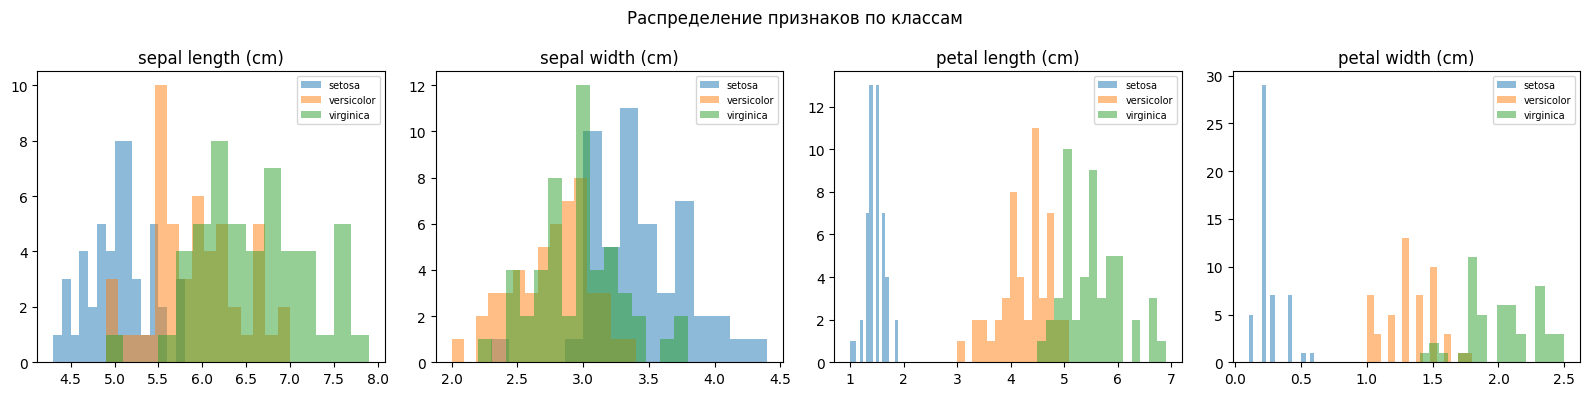

In [3]:
print("Пропуски по признакам:")
display(X.isna().sum())

print("\nБазовая статистика:")
display(X.describe().T)

# Визуализируем распределение одного признака по классам
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, col in enumerate(X.columns):
    for cls in range(3):
        axes[i].hist(X[col][y == cls], alpha=0.5, label=data.target_names[cls], bins=15)
    axes[i].set_title(col)
    axes[i].legend(fontsize=7)
plt.suptitle("Распределение признаков по классам")
plt.tight_layout()
plt.show()

## Шаг 1. Разделение данных

Ниже нужно:
1. разбить выборку на train и test;
2. получить `X_train`, `X_test`, `y_train`, `y_test`.

Подсказка:
- используйте `train_test_split(..., test_size=0.2, random_state=42, stratify=y)`.
- **Стандартизация здесь не нужна** — Наивный Байес сам оценивает параметры распределения по каждому признаку.

In [4]:
X_train, X_test, y_train, y_test =train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Распределение классов в train:", pd.Series(y_train).value_counts().to_dict())

Train shape: (120, 4)
Test shape: (30, 4)
Распределение классов в train: {0: 40, 2: 40, 1: 40}


## Шаг 2. Оцениваем априорные вероятности классов

Напишите функцию `compute_priors(y)`, которая возвращает словарь `{класс: P(класс)}`.

Проверка:
- сумма всех вероятностей должна быть равна `1.0`.

In [5]:
np.unique(y,return_counts=True)

(array([0, 1, 2]), array([50, 50, 50]))

In [6]:
def compute_priors(y):
    """
    Вычисляет априорные вероятности каждого класса.
    Возвращает словарь {класс: вероятность}.
    """
    classes,counts=np.unique(y,return_counts=True)
    total=len(y)
    priors={cls:count/total for cls, count in zip(classes,counts)}
    return priors

priors = compute_priors(y_train.values)
print("Априорные вероятности:", priors)
print("Сумма:", sum(priors.values()))

Априорные вероятности: {np.int64(0): np.float64(0.3333333333333333), np.int64(1): np.float64(0.3333333333333333), np.int64(2): np.float64(0.3333333333333333)}
Сумма: 1.0


## Шаг 3. Оцениваем параметры распределений по каждому классу

Для Гауссовского Наивного Байеса нужно по каждому классу и каждому признаку оценить:
- **среднее** `mu[c, j]` — среднее значение признака \(j\) в классе \(c\),
- **дисперсию** `var[c, j]` — дисперсию признака \(j\) в классе \(c\).

Напишите функцию `fit_gaussian_params(X, y)`, которая возвращает два массива: `means` и `variances` формы `(n_classes, n_features)`.

Подсказка:
- используйте `np.var(...)` — это **несмещённую** дисперсию лучше считать с `ddof=0` (по умолчанию).

In [7]:
def fit_gaussian_params(X, y):
    """
    Оценивает mu и var для каждого (класс, признак).
    X: np.array (n_samples, n_features)
    y: np.array (n_samples,)
    Возвращает: means (n_classes, n_features), variances (n_classes, n_features)
    """
    classes = np.unique(y)
    n_classes = len(classes)
    n_features = X.shape[1]

    means = np.zeros((n_classes, n_features))
    variances = np.zeros((n_classes, n_features))

    for i, c in enumerate(classes):

        X_c = X[y == c]

        means[i] = np.mean(X_c, axis=0)
        variances[i] = np.var(X_c, ddof=0, axis=0)

    return means, variances


X_train_np = X_train.values
y_train_np = y_train.values

means, variances = fit_gaussian_params(X_train_np, y_train_np)
print("means shape:", means.shape)
print("\nМатрица средних (класс x признак):")
display(pd.DataFrame(means, columns=data.feature_names, index=data.target_names).round(3))
print("\nМатрица дисперсий (класс x признак):")
display(pd.DataFrame(variances, columns=data.feature_names, index=data.target_names).round(4))

means shape: (3, 4)

Матрица средних (класс x признак):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,4.985,3.415,1.477,0.255
versicolor,5.930,2.750,4.252,1.320
virginica,6.610,2.980,5.580,2.040



Матрица дисперсий (класс x признак):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,0.0928,0.1553,0.0252,0.0130
versicolor,0.2216,0.0930,0.1915,0.0341
virginica,0.4574,0.1221,0.3236,0.0704


## Шаг 4. Вычисляем log-likelihood

Напишите функцию `gaussian_log_likelihood(x, mean, var)`, которая возвращает логарифм плотности нормального распределения:

$
\log P(x_j \mid c) = -\frac{1}{2}\log(2\pi\sigma^2) - \frac{(x_j - \mu)^2}{2\sigma^2}
$

Подсказка:
- `var` может быть очень маленьким — добавьте небольшую константу `eps=1e-9` к дисперсии во избежание деления на ноль.

In [8]:
def gaussian_log_likelihood(x, mean, var, eps=1e-9):
    """
    Считает log P(x | mu, sigma^2) по нормальному распределению.
    x: np.array (n_samples, n_features)
    mean: np.array (n_features,)
    var: np.array (n_features,)
    Возвращает: массив log-вероятностей для каждого объекта (n_samples,).
    """
    var_smoothed = var + eps

    term1 = -0.5 * np.log(2*np.pi*var_smoothed)

    term2 = -((x-mean)**2) / (2*var_smoothed)

    log_likelihood_per_sample = np.sum(term1 + term2, axis=1)

    return log_likelihood_per_sample


# Проверка: для одного объекта, одного класса
test_x = X_train_np[0]
ll = gaussian_log_likelihood(test_x.reshape(1, -1), means[0], variances[0])
print("Log-likelihood для первого объекта (класс 0):", ll[0])

Log-likelihood для первого объекта (класс 0): -0.47769884377699867


## Шаг 5. Собираем классификатор в класс

Допишите методы:
- `fit` — оценить прайоры, средние и дисперсии;
- `predict_log_proba` — вычислить логарифм апостериорной вероятности для каждого класса;
- `predict` — вернуть класс с наибольшей апостериорной вероятностью.

Требования:
- использовать логарифмы для численной стабильности;
- метод должен работать на `numpy`-массивах.

In [9]:
class MyGaussianNB:
    def __init__(self):
        self.classes_ = None
        self.log_priors_ = None  # логарифмы априорных вероятностей
        self.means_ = None       # (n_classes, n_features)
        self.variances_ = None   # (n_classes, n_features)

    def fit(self, X, y):
        """
        Оцениваем все параметры по обучающей выборке.
        """
        self.classes_ = np.unique(y)
        priors = compute_priors(y)

        self.log_priors_ = np.array([np.log(priors[cls]) for cls in self.classes_])
        self.means_, self.variances_ = fit_gaussian_params(X, y)

        return self

    def predict_log_proba(self, X):
        """
        Для каждого объекта и каждого класса вычисляет
        log P(c) + sum_j log P(x_j | c).
        Возвращает массив (n_samples, n_classes).
        """
        n_samples = X.shape[0]
        n_classes = len(self.classes_)

        log_proba = np.zeros((n_samples, n_classes))

        for i, cls in enumerate(self.classes_):
            log_prior = self.log_priors_[i]
            mean = self.means_[i]
            var = self.variances_[i]

            log_likelihood_for_class_i = gaussian_log_likelihood(X, mean, var)

            log_proba[:, i] = log_prior + log_likelihood_for_class_i

        return log_proba

    def predict(self, X):
        """
        Возвращает предсказанный класс для каждого объекта.
        """
        log_proba = self.predict_log_proba(X)
        pred_indices = np.argmax(log_proba, axis=1)

        preds = self.classes_[pred_indices]

        return preds

## Шаг 6. Обучаем свою модель

Обучите `MyGaussianNB` и убедитесь, что:
- модель обучилась без ошибок;
- параметры имеют ожидаемую форму.

In [10]:
my_model = MyGaussianNB()

my_model.fit(X_train_np,y_train_np)

print("Классы:", my_model.classes_)
print("Log-прайоры:", my_model.log_priors_)
print("Форма means_:", my_model.means_.shape)

Классы: [0 1 2]
Log-прайоры: [-1.09861229 -1.09861229 -1.09861229]
Форма means_: (3, 4)


## Шаг 7. Оценка качества своей модели

Заполните код ниже и посчитайте метрики на тестовой выборке:
- accuracy,
- precision (macro),
- recall (macro),
- f1 (macro).

In [11]:
X_test_np = X_test.values
y_test_np = y_test.values

my_pred_test =my_model.predict(X_test_np)

my_metrics = {
    "accuracy": accuracy_score(y_test_np,my_pred_test),
    "precision_macro": precision_score(y_test_np,my_pred_test,average='macro'),
    "recall_macro": recall_score(y_test_np,my_pred_test,average='macro'),
    "f1_macro": f1_score(y_test_np,my_pred_test,average='macro')
}

pd.Series(my_metrics).round(4)

,0
accuracy,0.9667
precision_macro,0.9697
recall_macro,0.9667
f1_macro,0.9666


## Шаг 8. Confusion matrix

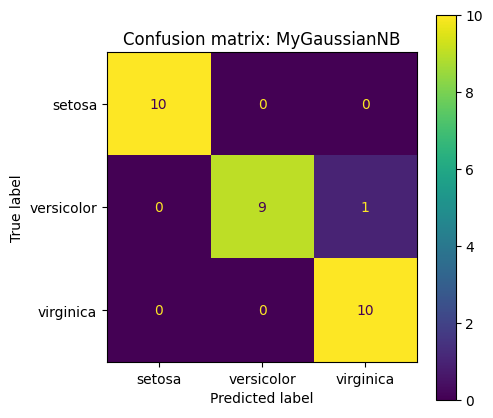

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [12]:
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_np, my_pred_test,
    display_labels=data.target_names,
    ax=ax
)
plt.title("Confusion matrix: MyGaussianNB")
plt.show()

print(classification_report(y_test_np, my_pred_test, target_names=data.target_names))

## Шаг 9. Сравнение с `scikit-learn`

Теперь обучите библиотечный `GaussianNB` и сравните его с вашей реализацией.

Рекомендации:
- используйте `GaussianNB()` без дополнительных параметров;
- обучайте на тех же данных `X_train_np`.

In [13]:
sk_model = GaussianNB()

sk_model.fit(X_train_np,y_train_np)
pred_test=sk_model.predict(X_test_np)

sk_metrics = {
    "accuracy":accuracy_score(y_test_np,pred_test),
    "precision_macro":precision_score(y_test_np,pred_test,average='macro'),
    "recall_macro": recall_score(y_test_np,pred_test,average='macro'),
    "f1_macro":f1_score(y_test_np,pred_test,average='macro'),
}

pd.Series(sk_metrics).round(4)

,0
accuracy,0.9667
precision_macro,0.9697
recall_macro,0.9667
f1_macro,0.9666


## Шаг 10. Сводная таблица сравнения

Сравните:
1. свою реализацию;
2. `scikit-learn`.

Также сравните оценённые параметры (средние) между реализациями.

Подумайте:
- почему результаты совпадают или отличаются;
- есть ли разница в том, как `sklearn` обрабатывает дисперсию (подсказка: посмотрите параметр `var_smoothing`).

In [14]:
comparison = pd.DataFrame(
    [my_metrics, sk_metrics],
    index=["my_model", "sklearn"]
)
display(comparison.round(4))

# Сравниваем оценённые средние
print("\nСредние MyGaussianNB:")
display(pd.DataFrame(my_model.means_, columns=data.feature_names, index=data.target_names).round(4))

print("\nСредние sklearn GaussianNB:")
# sk_model.theta_ содержит средние значения признаков для каждого класса
display(pd.DataFrame(sk_model.theta_, columns=data.feature_names, index=data.target_names).round(4))

,accuracy,precision_macro,recall_macro,f1_macro
my_model,0.9667,0.9697,0.9667,0.9666
sklearn,0.9667,0.9697,0.9667,0.9666



Средние MyGaussianNB:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,4.985,3.415,1.4775,0.255
versicolor,5.930,2.750,4.2525,1.320
virginica,6.610,2.980,5.5800,2.040



Средние sklearn GaussianNB:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,4.985,3.415,1.4775,0.255
versicolor,5.930,2.750,4.2525,1.320
virginica,6.610,2.980,5.5800,2.040


## Шаг 11. Проверяем допущение о независимости

Наивный Байес предполагает, что признаки **условно независимы** при данном классе.
Проверим, насколько это выполняется: вычислим корреляции между признаками внутри каждого класса.

Подумайте:
- какие пары признаков наиболее скоррелированы;
- нарушает ли это допущение о независимости;
- как это влияет на качество модели.

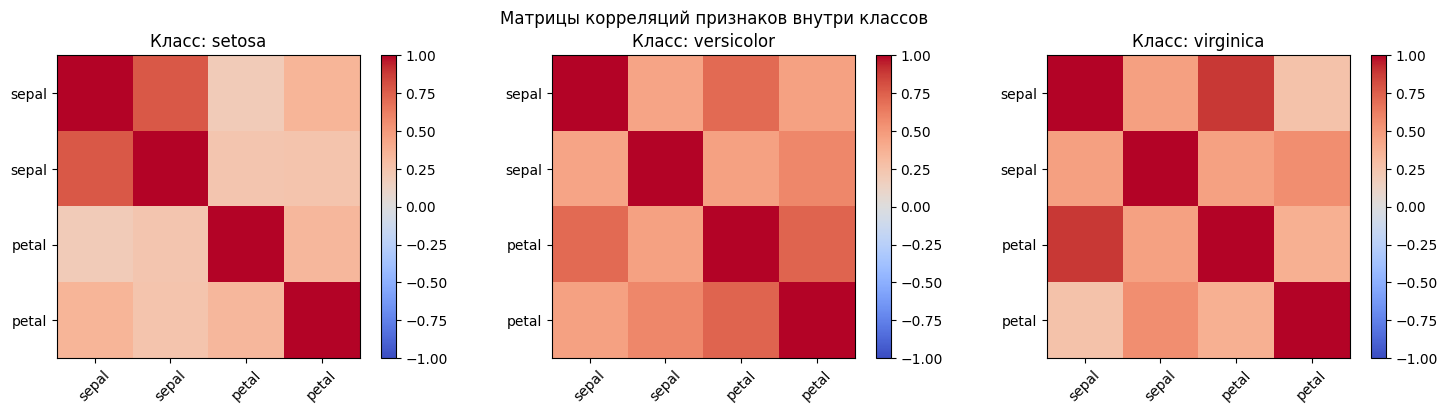

Корреляции для класса setosa:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000,0.775,0.194,0.348
sepal width (cm),0.775,1.000,0.241,0.249
petal length (cm),0.194,0.241,1.000,0.331
petal width (cm),0.348,0.249,0.331,1.000


Корреляции для класса versicolor:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000,0.444,0.710,0.459
sepal width (cm),0.444,1.000,0.458,0.582
petal length (cm),0.710,0.458,1.000,0.730
petal width (cm),0.459,0.582,0.730,1.000


Корреляции для класса virginca:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000,0.466,0.890,0.265
sepal width (cm),0.466,1.000,0.461,0.551
petal length (cm),0.890,0.461,1.000,0.380
petal width (cm),0.265,0.551,0.380,1.000


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for cls in range(3):
    X_cls = X_train[y_train == cls]
    corr = X_cls.corr()
    im = axes[cls].imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
    axes[cls].set_title(f"Класс: {data.target_names[cls]}")
    axes[cls].set_xticks(range(4))
    axes[cls].set_yticks(range(4))
    axes[cls].set_xticklabels([f.split(' ')[0] for f in data.feature_names], rotation=45)
    axes[cls].set_yticklabels([f.split(' ')[0] for f in data.feature_names])
    plt.colorbar(im, ax=axes[cls])

plt.suptitle("Матрицы корреляций признаков внутри классов")
plt.tight_layout()
plt.show()

print("Корреляции для класса setosa:")
display(X_train[y_train == 0].corr().round(3))

print("Корреляции для класса versicolor:")
display(X_train[y_train == 1].corr().round(3))

print("Корреляции для класса virginca:")
display(X_train[y_train == 2].corr().round(3))

## Финальные вопросы для ответа текстом

Ответьте кратко, но по существу.

1. В чём заключается «наивное» допущение Наивного Байеса? Почему его так называют?

Связанно с тем, что признаки условно независимы. Так как признаки чаще коррелируют, то допущение упрощено, но при этом эффиктивно.

2. Почему мы используем логарифм правдоподобия вместо самого правдоподобия?

Логарифм превращает произведение в сумму, сохраняет порядок сравнения классов и стабилизирует вычисления. Произведение многих вероятностей быстро стремится к нулю.

3. Почему для Гауссовского Наивного Байеса стандартизация данных **не нужна**?
Так как "наивный байес" не чуствителен к маштабу данных. Тут не применялось маштабирование данных, так как наивный байес этого не требует, так как работает с распределениями.

4. Насколько близки метрики вашей реализации к `scikit-learn`? Если есть расхождения — объясните их.

Метрики полностью совпали. Признаки могут расходится при разных значениях var_smoothing, неправильном суммировании логарифмов и занчений с нулевой дисперсией.

5. Посмотрите на матрицы корреляций: нарушается ли допущение о независимости признаков?

Да нарушается, некоторые признаки коррелируют, даже очень сильно >0.5

6. Когда Наивный Байес работает хорошо несмотря на нарушение допущения о независимости?

Когда классы хорошо разделимы,при высокой размерности и слабых сигналах.Когда коррелирующие признаки определяют границу решений в одну сторону.

7. Сравните Наивный Байес и Логистическую регрессию: когда предпочесть один метод другому?

Наивный Байес предпочтителен при малых выборках, очень высокой размерности/разреженности, когда нужна максимальная скорость обучения и устойчивость к шуму.

Логистическая регрессия лучше при достаточном объёме данных, наличии корреляций признаков, необходимости калиброванных вероятностей или интерпретируемых весов.

NB сходится быстрее асимптотически, но LogR обычно даёт выше качество на больших данных.

## Дополнительные задания

### Задание A
Добавьте параметр `var_smoothing` в `MyGaussianNB` (аналог `sklearn`): добавляйте к дисперсии небольшую долю от максимальной дисперсии по всем признакам. Посмотрите, как это влияет на метрики.

### Задание B
Попробуйте применить `MyGaussianNB` к датасету `Breast Cancer` (из семинара по логистической регрессии). Сравните качество с логистической регрессией. Объясните разницу.

### Задание C
Реализуйте `predict_proba` — метод, возвращающий нормированные вероятности (не логарифмы). Для этого:
- вычислите `log_proba`,
- вычтите максимум (для численной стабильности),
- примените `exp`,
- нормируйте на сумму.

### Задание A
Добавьте параметр `var_smoothing` в `MyGaussianNB` (аналог `sklearn`): добавляйте к дисперсии небольшую долю от максимальной дисперсии по всем признакам. Посмотрите, как это влияет на метрики.

In [16]:
class MyGaussianNB2:
    def __init__(self, var_smoothing=1e-9):
        self.classes_ = None
        self.log_priors_ = None  # логарифмы априорных вероятностей
        self.means_ = None       # (n_classes, n_features)
        self.variances_ = None   # (n_classes, n_features)
        self.var_smoothing = var_smoothing
        self._epsilon_ = None

    def fit(self, X, y):
        """
        Оцениваем все параметры по обучающей выборке.
        """
        self.classes_ = np.unique(y)
        priors = compute_priors(y)

        self.log_priors_ = np.array([np.log(priors[cls]) for cls in self.classes_])
        self.means_, self.variances_ = fit_gaussian_params(X, y)

        max_variance = np.max(self.variances_) if self.variances_.size > 0 else 0
        self._epsilon_ = self.var_smoothing * max_variance if max_variance > 0 else self.var_smoothing

        return self

    def predict_log_proba(self, X):
        """
        Для каждого объекта и каждого класса вычисляет
        log P(c) + sum_j log P(x_j | c).
        Возвращает массив (n_samples, n_classes).
        """
        n_samples = X.shape[0]
        n_classes = len(self.classes_)

        log_proba = np.zeros((n_samples, n_classes))

        for i, cls in enumerate(self.classes_):
            log_prior = self.log_priors_[i]
            mean = self.means_[i]
            var = self.variances_[i]

            log_likelihood_for_class_i = gaussian_log_likelihood(X, mean, var, eps=self._epsilon_)

            log_proba[:, i] = log_prior + log_likelihood_for_class_i

        return log_proba

    def predict(self, X):
        """
        Возвращает предсказанный класс для каждого объекта.
        """
        log_proba = self.predict_log_proba(X)
        pred_indices = np.argmax(log_proba, axis=1)

        preds = self.classes_[pred_indices]

        return preds

In [17]:
X_train_np = X_train.values
y_train_np = y_train.values

In [18]:
my_model = MyGaussianNB2(var_smoothing=1e-1)

my_model.fit(X_train_np,y_train_np)

print("Классы:", my_model.classes_)
print("Log-прайоры:", my_model.log_priors_)
print("Форма means_:", my_model.means_.shape)

Классы: [0 1 2]
Log-прайоры: [-1.09861229 -1.09861229 -1.09861229]
Форма means_: (3, 4)


In [19]:
X_test_np = X_test.values
y_test_np = y_test.values

my_pred_test =my_model.predict(X_test_np)

my_metrics = {
    "accuracy": accuracy_score(y_test_np,my_pred_test),
    "precision_macro": precision_score(y_test_np,my_pred_test,average='macro'),
    "recall_macro": recall_score(y_test_np,my_pred_test,average='macro'),
    "f1_macro": f1_score(y_test_np,my_pred_test,average='macro')
}

pd.Series(my_metrics).round(4)

,0
accuracy,0.9667
precision_macro,0.9697
recall_macro,0.9667
f1_macro,0.9666


In [20]:
for vs in [1e-9, 1e-3, 1e-1, 0.5, 1, 10]:
    model = MyGaussianNB2(var_smoothing=vs)
    model.fit(X_train_np, y_train_np)
    pred = model.predict(X_test_np)
    print(vs, accuracy_score(y_test_np, pred))

1e-09 0.9666666666666667
0.001 0.9666666666666667
0.1 0.9666666666666667
0.5 0.9
1 0.9
10 0.9


 При маленьких значениях `var_smoothing` (от `1e-9` до `1e-1`) качество модели остается стабильно высоким и неизменным (Accuracy = `96.67%`). Это говорит о том, что дисперсии признаков в датасете Iris достаточно велики, и нам не требуется сильное искусственное сглаживание для предотвращения деления на ноль.

 Но:

 Как только я увеличиваю `var_smoothing` до `0.5` и выше, точность падает до `90.0%`.
 Параметр `var_smoothing` искусственно завышает дисперсию признаков (прибавляя к ней часть от максимальной дисперсии). Когда дисперсия становится слишком большой, нормальное распределение для каждого класса «растекается» и становится очень плоским. В результате модель начинает считать, что все классы распределены примерно одинаково широко, стирая реальные различия между ними. Модель теряет чувствительность к признакам и начинает предсказывать хуже.

In [21]:
comparison = pd.DataFrame(
    [my_metrics, sk_metrics],
    index=["my_model", "sklearn"]
)
display(comparison.round(4))

# Сравниваем оценённые средние
print("\nСредние MyGaussianNB2:")
display(pd.DataFrame(my_model.means_, columns=data.feature_names, index=data.target_names).round(4))

print("\nСредние sklearn GaussianNB:")
# sk_model.theta_ содержит средние значения признаков для каждого класса
display(pd.DataFrame(sk_model.theta_, columns=data.feature_names, index=data.target_names).round(4))

,accuracy,precision_macro,recall_macro,f1_macro
my_model,0.9667,0.9697,0.9667,0.9666
sklearn,0.9667,0.9697,0.9667,0.9666



Средние MyGaussianNB2:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,4.985,3.415,1.4775,0.255
versicolor,5.930,2.750,4.2525,1.320
virginica,6.610,2.980,5.5800,2.040



Средние sklearn GaussianNB:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,4.985,3.415,1.4775,0.255
versicolor,5.930,2.750,4.2525,1.320
virginica,6.610,2.980,5.5800,2.040


Значения сильно малы, поэтому сильного вляиния не будет заметно.

### Задание B
Попробуйте применить `MyGaussianNB` к датасету `Breast Cancer` (из семинара по логистической регрессии). Сравните качество с логистической регрессией. Объясните разницу.

In [22]:
from sklearn.datasets import load_breast_cancer

In [23]:
data=load_breast_cancer()
X=pd.DataFrame(data.data,columns=data.feature_names)
y=pd.Series(data.target,name="target")

print("Размер X:", X.shape)
print("Размер y:", y.shape)
display(X.head())

Размер X: (569, 30)
Размер y: (569,)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [24]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler = StandardScaler()
X_train_scaled =scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train_scaled.shape)
print("Test shape:", X_test_scaled.shape)

Train shape: (455, 30)
Test shape: (114, 30)


In [25]:
X_train_np = X_train.values
y_train_np = y_train.values

In [26]:
model_b = MyGaussianNB2(var_smoothing=1e-9)
model_b.fit(X_train_scaled, y_train_np)
nb_pred = model_b.predict(X_test_scaled)
print("Классы:", model_b.classes_)
print("Log-прайоры:", model_b.log_priors_)
print("Форма means_:", model_b.means_.shape)
print("Предсказания:", nb_pred)


Классы: [0 1]
Log-прайоры: [-0.98449898 -0.46780824]
Форма means_: (2, 30)
Предсказания: [0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 0 1 1 1 0 1 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 0 0 0
 0 1 1]


In [27]:
model_sk = GaussianNB()
model_sk.fit(X_train_scaled, y_train_np)
model_pred = model_sk.predict(X_test_scaled)

print("Классы:", model_sk.classes_)
print("Форма theta_:", model_sk.theta_.shape)
print("Предсказания:", model_pred)

Классы: [0 1]
Форма theta_: (2, 30)
Предсказания: [0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 0 1 1 1 0 1 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 0 0 0
 0 1 1]


In [28]:
X_test_np = X_test.values
y_test_np = y_test.values


my_metrics = {
    "accuracy": accuracy_score(y_test_np, model_pred),
    "precision_macro": precision_score(y_test_np, model_pred, average='macro'),
    "recall_macro": recall_score(y_test_np, model_pred, average='macro'),
    "f1_macro": f1_score(y_test_np, model_pred, average='macro')
}

pd.Series(my_metrics).round(4)

,0
accuracy,0.9298
precision_macro,0.9246
recall_macro,0.9246
f1_macro,0.9246


In [29]:
my_metrics2 = {
    "accuracy": accuracy_score(y_test_np, nb_pred),
    "precision_macro": precision_score(y_test_np, nb_pred,average='macro'),
    "recall_macro": recall_score(y_test_np, nb_pred,average='macro'),
    "f1_macro": f1_score(y_test_np, nb_pred,average='macro')
}

pd.Series(my_metrics).round(4)

,0
accuracy,0.9298
precision_macro,0.9246
recall_macro,0.9246
f1_macro,0.9246


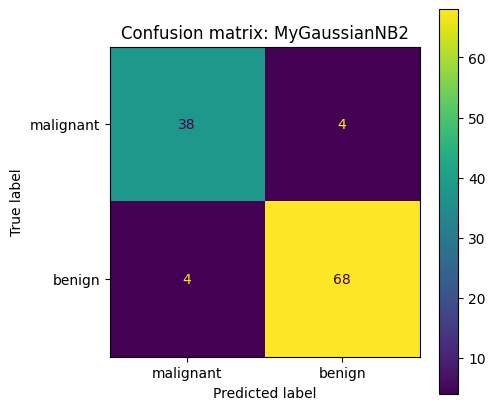

              precision    recall  f1-score   support

   malignant       0.90      0.90      0.90        42
      benign       0.94      0.94      0.94        72

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



In [30]:
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_np, nb_pred,
    display_labels=data.target_names,
    ax=ax
)
plt.title("Confusion matrix: MyGaussianNB2")
plt.show()

print(classification_report(y_test_np, nb_pred, target_names=data.target_names))

In [31]:
log_reg_model = LogisticRegression(random_state=42, solver='liblinear')
log_reg_model.fit(X_train_scaled, y_train)

log_reg_pred_test = log_reg_model.predict(X_test_scaled)

log_reg_metrics = {
    "accuracy": accuracy_score(y_test, log_reg_pred_test),
    "precision_macro": precision_score(y_test, log_reg_pred_test, average='macro'),
    "recall_macro": recall_score(y_test, log_reg_pred_test, average='macro'),
    "f1_macro": f1_score(y_test, log_reg_pred_test, average='macro'),
}

print("\nМетрики MyGaussianNB (Breast Cancer):")
display(pd.Series(my_metrics).round(4))

print("\nМетрики MyGaussianNB2 (Breast Cancer):")
display(pd.Series(my_metrics2).round(4))

print("\nМетрики Logistic Regression (Breast Cancer):")
display(pd.Series(log_reg_metrics).round(4))


Метрики MyGaussianNB (Breast Cancer):


,0
accuracy,0.9298
precision_macro,0.9246
recall_macro,0.9246
f1_macro,0.9246



Метрики MyGaussianNB2 (Breast Cancer):


,0
accuracy,0.9298
precision_macro,0.9246
recall_macro,0.9246
f1_macro,0.9246



Метрики Logistic Regression (Breast Cancer):


,0
accuracy,0.9825
precision_macro,0.9812
recall_macro,0.9812
f1_macro,0.9812


In [32]:
# Сравним минимальную и максимальную дисперсию исходных признаков
raw_vars = X_train.var(ddof=0)
print(f"Минимальная дисперсия признака: {raw_vars.min():.6f} ({raw_vars.idxmin()})")
print(f"Максимальная дисперсия признака: {raw_vars.max():.2f} ({raw_vars.idxmax()})")
print(f"Отношение макс/мин дисперсии: {raw_vars.max() / raw_vars.min():.2e}")

Минимальная дисперсия признака: 0.000008 (fractal dimension error)
Максимальная дисперсия признака: 305056.24 (worst area)
Отношение макс/мин дисперсии: 3.96e+10


In [33]:
# Обучение на несвязанных (raw) значениях
model_raw = MyGaussianNB2(var_smoothing=1e-9)
model_raw.fit(X_train.values, y_train_np)
preds_raw = model_raw.predict(X_test.values)

print("Распределение предсказаний без StandardScaler:")
print(pd.Series(preds_raw).value_counts())

print("\nРаспределение реальных классов в тесте:")
print(pd.Series(y_test_np).value_counts())

Распределение предсказаний без StandardScaler:
1    73
0    41
Name: count, dtype: int64

Распределение реальных классов в тесте:
1    72
0    42
Name: count, dtype: int64


### Выводы по Заданию B (Breast Cancer)

1. **Анализ полученных результатов:**
   * **Логистическая регрессия** продемонстрировала превосходное качество классификации с метрикой **Accuracy $\approx 98.2\%$** ($F_1 \approx 98.1\%$).
   * **Наивный Байесовский классификатор** (как `MyGaussianNB2`, так и библиотечный `GaussianNB`) показал заметно более низкий результат с **Accuracy $\approx 93.0\%$** ($F_1 \approx 92.5\%$).

2. **Причины расхождения в качестве моделей:**
   * **Мультиколлинеарность (сильная корреляция признаков):** Главное допущение Наивного Байеса состоит в условной независимости признаков при заданном классе. В датасете *Breast Cancer* многие признаки описывают схожие свойства (например, *mean radius*, *mean perimeter*, *mean area* практически линейно зависимы). Из-за нарушения этого допущения Наивный Байес многократно суммирует вклады взаимосвязанных признаков, искусственно завышая уверенность в ошибочных прогнозах.
   * **Характер разделяющей границы:** Логистическая регрессия строит разделяющую гиперплоскость напрямую путем минимизации потерь, что позволяет ей находить оптимальные веса для коррелирующих признаков. Наивный Байес оценивает плотности распределений каждого класса независимо и не оптимизирует границу принятия решений напрямую.

3. **Роль масштабирования данных:**
   * Логистическая регрессия крайне чувствительна к масштабу признаков, так как регуляризация одинаково штрафует веса признаков разного масштаба.
   * Наивный Байес работает независимо с каждым признаком (оценивая его собственное среднее и дисперсию), поэтому стандартизация данных никак не влияет на качество его предсказаний.

### Задание C
Реализуйте `predict_proba` — метод, возвращающий нормированные вероятности (не логарифмы). Для этого:
- вычислите `log_proba`,
- вычтите максимум (для численной стабильности),
- примените `exp`,
- нормируйте на сумму.

In [34]:
class MyGaussianNB2:
    def __init__(self, var_smoothing=1e-9):
        self.classes_ = None
        self.log_priors_ = None  # логарифмы априорных вероятностей
        self.means_ = None       # (n_classes, n_features)
        self.variances_ = None   # (n_classes, n_features)
        self.var_smoothing = var_smoothing
        self._epsilon_ = None


    def predict_proba(self, X):
      log_proba=self.predict_log_proba(X)
      log_proba_two=log_proba-np.max(log_proba,axis=1,keepdims=True)
      log_proba_exp=np.exp(log_proba_two)
      pred_proba=log_proba_exp/np.sum(log_proba_exp,axis=1,keepdims=True)

      return pred_proba

    def fit(self, X, y):
        """
        Оцениваем все параметры по обучающей выборке.
        """
        self.classes_ = np.unique(y)
        priors = compute_priors(y)

        self.log_priors_ = np.array([np.log(priors[cls]) for cls in self.classes_])
        self.means_, self.variances_ = fit_gaussian_params(X, y)

        max_variance = np.max(self.variances_) if self.variances_.size > 0 else 0
        self._epsilon_ = self.var_smoothing * max_variance if max_variance > 0 else self.var_smoothing

        return self

    def predict_log_proba(self, X):
        """
        Для каждого объекта и каждого класса вычисляет
        log P(c) + sum_j log P(x_j | c).
        Возвращает массив (n_samples, n_classes).
        """
        n_samples = X.shape[0]
        n_classes = len(self.classes_)

        log_proba = np.zeros((n_samples, n_classes))

        for i, cls in enumerate(self.classes_):
            log_prior = self.log_priors_[i]
            mean = self.means_[i]
            var = self.variances_[i]

            log_likelihood_for_class_i = gaussian_log_likelihood(X, mean, var, eps=self._epsilon_)

            log_proba[:, i] = log_prior + log_likelihood_for_class_i

        return log_proba

    def predict(self, X):
        """
        Возвращает предсказанный класс для каждого объекта.
        """
        log_proba = self.predict_log_proba(X)
        pred_indices = np.argmax(log_proba, axis=1)

        preds = self.classes_[pred_indices]

        return preds

In [37]:
model = MyGaussianNB2()
model.fit(X_train_np, y_train_np)
proba = model.predict_proba(X_test_np)
print(proba.sum(axis=1)[:5])
print(np.abs(proba - GaussianNB().fit(X_train_np, y_train_np).predict_proba(X_test_np)).max())

[1. 1. 1. 1. 1.]
0.02162528933903113


## Что должно получиться в итоге

После заполнения ноутбука у вас должен быть полный pipeline:

- загрузка данных;
- train/test split;
- оценка параметров Гауссовского Наивного Байеса с нуля;
- классификация по правилу Байеса;
- метрики качества;
- сравнение со `scikit-learn`;
- анализ допущения о независимости;
- выводы.

Не сдавайте ноутбук без текстовых выводов.